# Classifiez automatiquement des informations

# Cellule recap

## 1. Import des modules et du dataset

In [445]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
import numpy as np
from sklearn import preprocessing

pd.set_option("display.max_columns", 200)

In [446]:
df_sirh = pd.read_csv("../data/raw/extrait_sirh.csv")
df_evaluation = pd.read_csv("../data/raw/extrait_eval.csv")
df_sondage = pd.read_csv("../data/raw/extrait_sondage.csv")

## 2. Analyse exploratoire

### A. SIRH

In [447]:
df_sirh.info()
display("Nombre de doublons : " + str(df_sirh.duplicated().sum()))

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 12 columns):
 #   Column                          Non-Null Count  Dtype
---  ------                          --------------  -----
 0   id_employee                     1470 non-null   int64
 1   age                             1470 non-null   int64
 2   genre                           1470 non-null   str  
 3   revenu_mensuel                  1470 non-null   int64
 4   statut_marital                  1470 non-null   str  
 5   departement                     1470 non-null   str  
 6   poste                           1470 non-null   str  
 7   nombre_experiences_precedentes  1470 non-null   int64
 8   nombre_heures_travailless       1470 non-null   int64
 9   annee_experience_totale         1470 non-null   int64
 10  annees_dans_l_entreprise        1470 non-null   int64
 11  annees_dans_le_poste_actuel     1470 non-null   int64
dtypes: int64(8), str(4)
memory usage: 137.9 KB


'Nombre de doublons : 0'

### B. Evaluation

In [448]:
df_evaluation.info()
display("Nombre de doublons : " + str(df_evaluation.duplicated().sum()))


<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 10 columns):
 #   Column                                     Non-Null Count  Dtype
---  ------                                     --------------  -----
 0   satisfaction_employee_environnement        1470 non-null   int64
 1   note_evaluation_precedente                 1470 non-null   int64
 2   niveau_hierarchique_poste                  1470 non-null   int64
 3   satisfaction_employee_nature_travail       1470 non-null   int64
 4   satisfaction_employee_equipe               1470 non-null   int64
 5   satisfaction_employee_equilibre_pro_perso  1470 non-null   int64
 6   eval_number                                1470 non-null   str  
 7   note_evaluation_actuelle                   1470 non-null   int64
 8   heure_supplementaires                      1470 non-null   str  
 9   augementation_salaire_precedente           1470 non-null   str  
dtypes: int64(7), str(3)
memory usage: 115.0 KB


'Nombre de doublons : 0'

### C. Sondage

In [449]:
df_sondage.info()
display("Nombre de doublons : " + str(df_sondage.duplicated().sum()))

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 12 columns):
 #   Column                               Non-Null Count  Dtype
---  ------                               --------------  -----
 0   a_quitte_l_entreprise                1470 non-null   str  
 1   nombre_participation_pee             1470 non-null   int64
 2   nb_formations_suivies                1470 non-null   int64
 3   nombre_employee_sous_responsabilite  1470 non-null   int64
 4   code_sondage                         1470 non-null   int64
 5   distance_domicile_travail            1470 non-null   int64
 6   niveau_education                     1470 non-null   int64
 7   domaine_etude                        1470 non-null   str  
 8   ayant_enfants                        1470 non-null   str  
 9   frequence_deplacement                1470 non-null   str  
 10  annees_depuis_la_derniere_promotion  1470 non-null   int64
 11  annes_sous_responsable_actuel        1470 non-null   int64
dtypes: 

'Nombre de doublons : 0'

Les features **id_employee**, **eval_number** et **code_sondage** sont potentiellement de bons candidats pour la jointure des dataframe.

In [450]:
display(df_sondage["code_sondage"].head(10))
display(df_sirh["id_employee"].head(10))
display(df_evaluation["eval_number"].head(10))

0     1
1     2
2     4
3     5
4     7
5     8
6    10
7    11
8    12
9    13
Name: code_sondage, dtype: int64

0     1
1     2
2     4
3     5
4     7
5     8
6    10
7    11
8    12
9    13
Name: id_employee, dtype: int64

0     E_1
1     E_2
2     E_4
3     E_5
4     E_7
5     E_8
6    E_10
7    E_11
8    E_12
9    E_13
Name: eval_number, dtype: str

Il semble que la distribution soit similaire. <br> En retirant **E_** de la colonne **eval_number**, on pourra procéder à notre jointure.

In [451]:
df_evaluation["eval_number"] = df_evaluation["eval_number"].apply(lambda x: int(x.replace('E_', '')))

In [452]:
df = df_sirh
df = df.merge(df_sondage, left_on="id_employee", right_on="code_sondage")
df = df.merge(df_evaluation, left_on="id_employee", right_on="eval_number")

In [453]:
df.describe(include='all')

,id_employee,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,nombre_heures_travailless,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel,a_quitte_l_entreprise,nombre_participation_pee,nb_formations_suivies,nombre_employee_sous_responsabilite,code_sondage,distance_domicile_travail,niveau_education,domaine_etude,ayant_enfants,frequence_deplacement,annees_depuis_la_derniere_promotion,annes_sous_responsable_actuel,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,eval_number,note_evaluation_actuelle,heure_supplementaires,augementation_salaire_precedente
count,1470.000000,1470.000000,1470,1470.000000,1470,1470,1470,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470,1470,1470,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470,1470
unique,NaN,NaN,2,NaN,3,3,9,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,6,1,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,15
top,NaN,NaN,M,NaN,Marié(e),Consulting,Cadre Commercial,NaN,NaN,NaN,NaN,NaN,Non,NaN,NaN,NaN,NaN,NaN,NaN,Infra & Cloud,Y,Occasionnel,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Non,11 %
freq,NaN,NaN,882,NaN,673,961,326,NaN,NaN,NaN,NaN,NaN,1233,NaN,NaN,NaN,NaN,NaN,NaN,606,1470,1043,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1054,210
mean,1024.865306,36.923810,NaN,6502.931293,NaN,NaN,NaN,2.693197,80.0,11.279592,7.008163,4.229252,NaN,0.793878,2.799320,1.0,1024.865306,9.192517,2.912925,NaN,NaN,NaN,2.187755,4.123129,2.721769,2.729932,2.063946,2.728571,2.712245,2.761224,1024.865306,3.153741,NaN,NaN
std,602.024335,9.135373,NaN,4707.956783,NaN,NaN,NaN,2.498009,0.0,7.780782,6.126525,3.623137,NaN,0.852077,1.289271,0.0,602.024335,8.106864,1.024165,NaN,NaN,NaN,3.222430,3.568136,1.093082,0.711561,1.106940,1.102846,1.081209,0.706476,602.024335,0.360824,NaN,NaN
min,1.000000,18.000000,NaN,1009.000000,NaN,NaN,NaN,0.000000,80.0,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,1.0,1.000000,1.000000,1.000000,NaN,NaN,NaN,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.000000,NaN,NaN
25%,491.250000,30.000000,NaN,2911.000000,NaN,NaN,NaN,1.000000,80.0,6.000000,3.000000,2.000000,NaN,0.000000,2.000000,1.0,491.250000,2.000000,2.000000,NaN,NaN,NaN,0.000000,2.000000,2.000000,2.000000,1.000000,2.000000,2.000000,2.000000,491.250000,3.000000,NaN,NaN
50%,1020.500000,36.000000,NaN,4919.000000,NaN,NaN,NaN,2.000000,80.0,10.000000,5.000000,3.000000,NaN,1.000000,3.000000,1.0,1020.500000,7.000000,3.000000,NaN,NaN,NaN,1.000000,3.000000,3.000000,3.000000,2.000000,3.000000,3.000000,3.000000,1020.500000,3.000000,NaN,NaN
75%,1555.750000,43.000000,NaN,8379.000000,NaN,NaN,NaN,4.000000,80.0,15.000000,9.000000,7.000000,NaN,1.000000,3.000000,1.0,1555.750000,14.000000,4.000000,NaN,NaN,NaN,3.000000,7.000000,4.000000,3.000000,3.000000,4.000000,4.000000,3.000000,1555.750000,3.000000,NaN,NaN


Les colonnes **eval_number**, **code_sondage** et **id_employe** ont une distribution identique et chaque valeur est unique <br> Les colonnes **ayant_enfants**, **nombre_employee_sous_responsabilite** et **nombre_heures_travailless**  contiennent une valeur unique, ce qui les rendent inexploitables en plus d'être improbable<br>On peut donc supprimer ces colonnes.

In [454]:
df = df.drop(["eval_number", "code_sondage", "ayant_enfants", "id_employee", "nombre_employee_sous_responsabilite", "nombre_heures_travailless"], axis=1)

Afin de rendre la colonne augementation_salaire_precedente exploitable, on va la transformer en une colonne d'entier.

In [455]:
# On corrige la faute dans le libellé de la colonne
df = df.rename(columns={'augementation_salaire_precedente': 'augmentation_salaire_precedente'})

df["augmentation_salaire_precedente"] = df["augmentation_salaire_precedente"].apply(lambda x: int(x.replace(' %', '')))

In [456]:
df.describe(include='all')

,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel,a_quitte_l_entreprise,nombre_participation_pee,nb_formations_suivies,distance_domicile_travail,niveau_education,domaine_etude,frequence_deplacement,annees_depuis_la_derniere_promotion,annes_sous_responsable_actuel,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,note_evaluation_actuelle,heure_supplementaires,augmentation_salaire_precedente
count,1470.000000,1470,1470.000000,1470,1470,1470,1470.000000,1470.000000,1470.000000,1470.000000,1470,1470.000000,1470.000000,1470.000000,1470.000000,1470,1470,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470,1470.000000
unique,NaN,2,NaN,3,3,9,NaN,NaN,NaN,NaN,2,NaN,NaN,NaN,NaN,6,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN
top,NaN,M,NaN,Marié(e),Consulting,Cadre Commercial,NaN,NaN,NaN,NaN,Non,NaN,NaN,NaN,NaN,Infra & Cloud,Occasionnel,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Non,NaN
freq,NaN,882,NaN,673,961,326,NaN,NaN,NaN,NaN,1233,NaN,NaN,NaN,NaN,606,1043,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1054,NaN
mean,36.923810,NaN,6502.931293,NaN,NaN,NaN,2.693197,11.279592,7.008163,4.229252,NaN,0.793878,2.799320,9.192517,2.912925,NaN,NaN,2.187755,4.123129,2.721769,2.729932,2.063946,2.728571,2.712245,2.761224,3.153741,NaN,15.209524
std,9.135373,NaN,4707.956783,NaN,NaN,NaN,2.498009,7.780782,6.126525,3.623137,NaN,0.852077,1.289271,8.106864,1.024165,NaN,NaN,3.222430,3.568136,1.093082,0.711561,1.106940,1.102846,1.081209,0.706476,0.360824,NaN,3.659938
min,18.000000,NaN,1009.000000,NaN,NaN,NaN,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,1.000000,1.000000,NaN,NaN,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.000000,NaN,11.000000
25%,30.000000,NaN,2911.000000,NaN,NaN,NaN,1.000000,6.000000,3.000000,2.000000,NaN,0.000000,2.000000,2.000000,2.000000,NaN,NaN,0.000000,2.000000,2.000000,2.000000,1.000000,2.000000,2.000000,2.000000,3.000000,NaN,12.000000
50%,36.000000,NaN,4919.000000,NaN,NaN,NaN,2.000000,10.000000,5.000000,3.000000,NaN,1.000000,3.000000,7.000000,3.000000,NaN,NaN,1.000000,3.000000,3.000000,3.000000,2.000000,3.000000,3.000000,3.000000,3.000000,NaN,14.000000
75%,43.000000,NaN,8379.000000,NaN,NaN,NaN,4.000000,15.000000,9.000000,7.000000,NaN,1.000000,3.000000,14.000000,4.000000,NaN,NaN,3.000000,7.000000,4.000000,3.000000,3.000000,4.000000,4.000000,3.000000,3.000000,NaN,18.000000


## 3. Analyse Univarié

Text(0.5, 1.0, 'Histogramme de age')

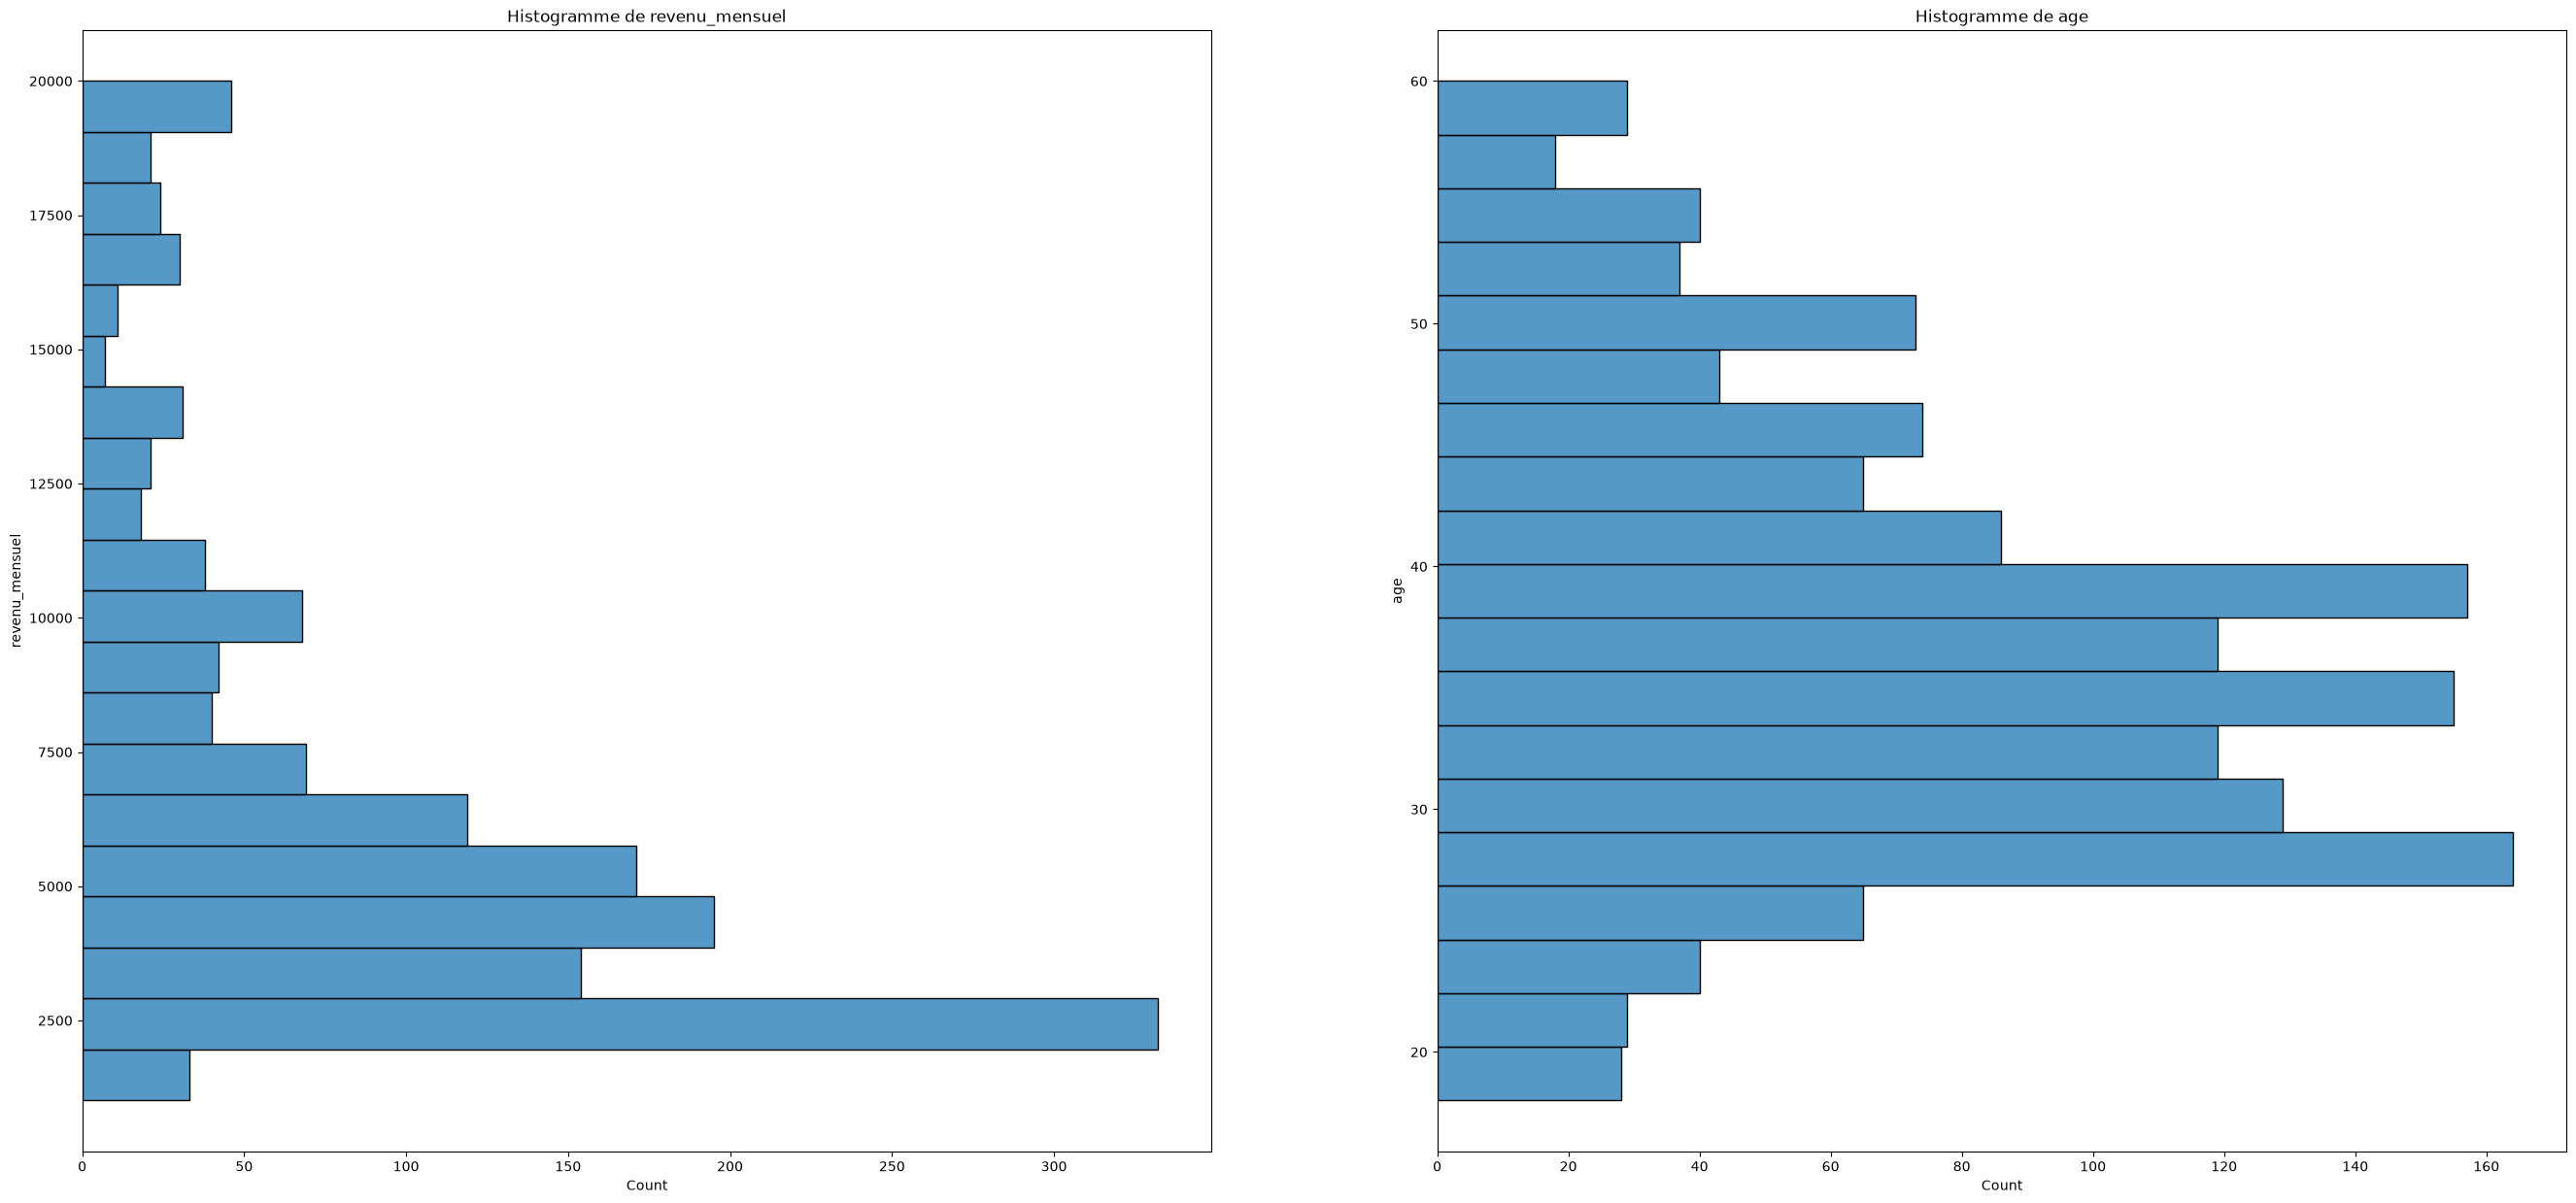

In [457]:
fig, axes = plt.subplots(1, 2, figsize=(33,15))
sns.histplot(data=df, y="revenu_mensuel", ax=axes[0]).set_title("Histogramme de revenu_mensuel")
sns.histplot(data=df, y="age", ax=axes[1]).set_title("Histogramme de age")


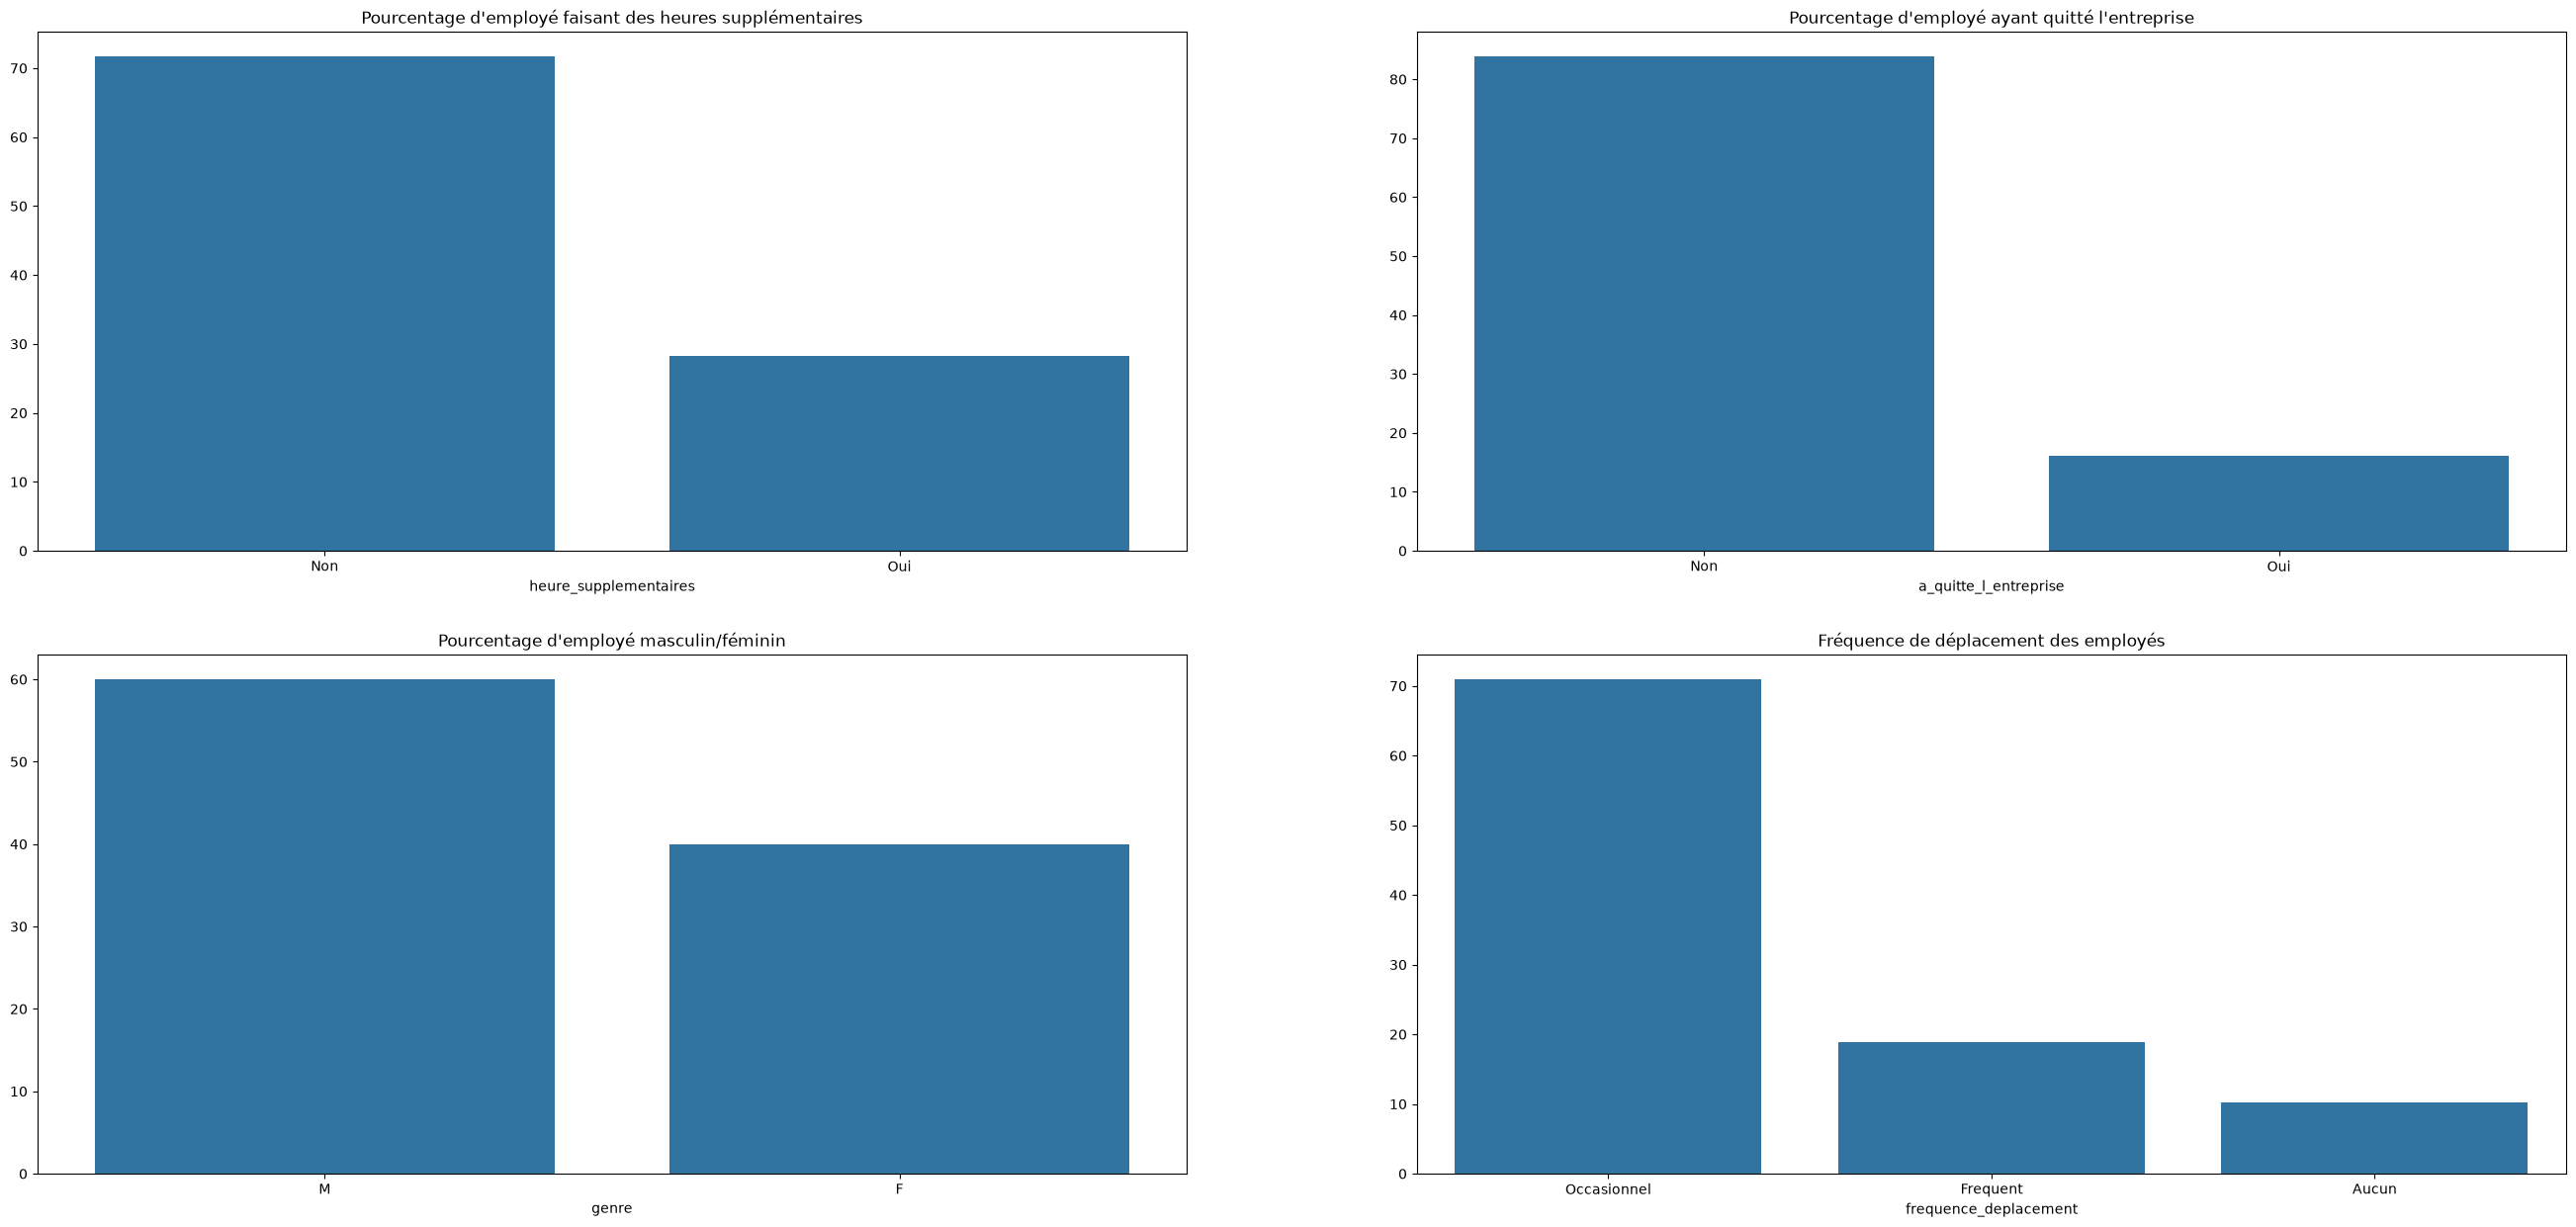

In [ ]:
df_heure_supp_pourcentage = df["heure_supplementaires"].value_counts(normalize=True) * 100
df_a_quitte_l_entreprise_pourcentage = df["a_quitte_l_entreprise"].value_counts(normalize=True) * 100
df_genre_pourcentage = df["genre"].value_counts(normalize=True) * 100
df_frequence_deplacement_pourcentage = df["frequence_deplacement"].value_counts(normalize=True) * 100

fig, axes = plt.subplots(2, 2, figsize=(33,15))

sns.barplot(x=df_heure_supp_pourcentage.index, y=df_heure_supp_pourcentage.values, ax=axes[0][0]).set_title("Pourcentage d'employé faisant des heures supplémentaires")
sns.barplot(x=df_a_quitte_l_entreprise_pourcentage.index, y=df_a_quitte_l_entreprise_pourcentage.values,
             ax=axes[0][1]).set_title("Pourcentage d'employé ayant quitté l'entreprise")
sns.barplot(x=df_genre_pourcentage.index, y=df_genre_pourcentage.values, ax=axes[1][0]).set_title("Pourcentage d'employé masculin/féminin")
sns.barplot(x=df_frequence_deplacement_pourcentage.index, y=df_frequence_deplacement_pourcentage.values,
             ax=axes[1][1]).set_title("Fréquence de déplacement des employés")

plt.show()

Répartition des différents postes

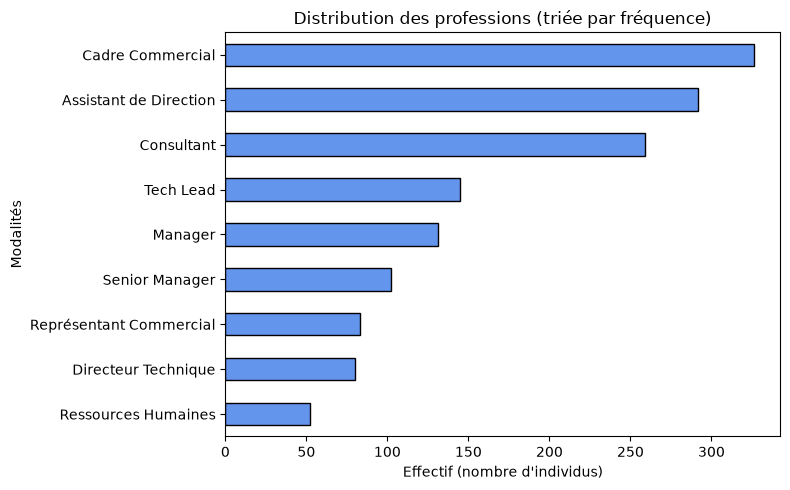

In [441]:
effectifs_tries = df['poste'].value_counts()


plt.figure(figsize=(8, 5))
effectifs_tries.plot(kind='barh', color='cornflowerblue', edgecolor='black')


plt.title("Distribution des professions (triée par fréquence)")
plt.xlabel("Effectif (nombre d'individus)")
plt.ylabel("Modalités")


plt.gca().invert_yaxis()


plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Boxplot du revenu par departement')

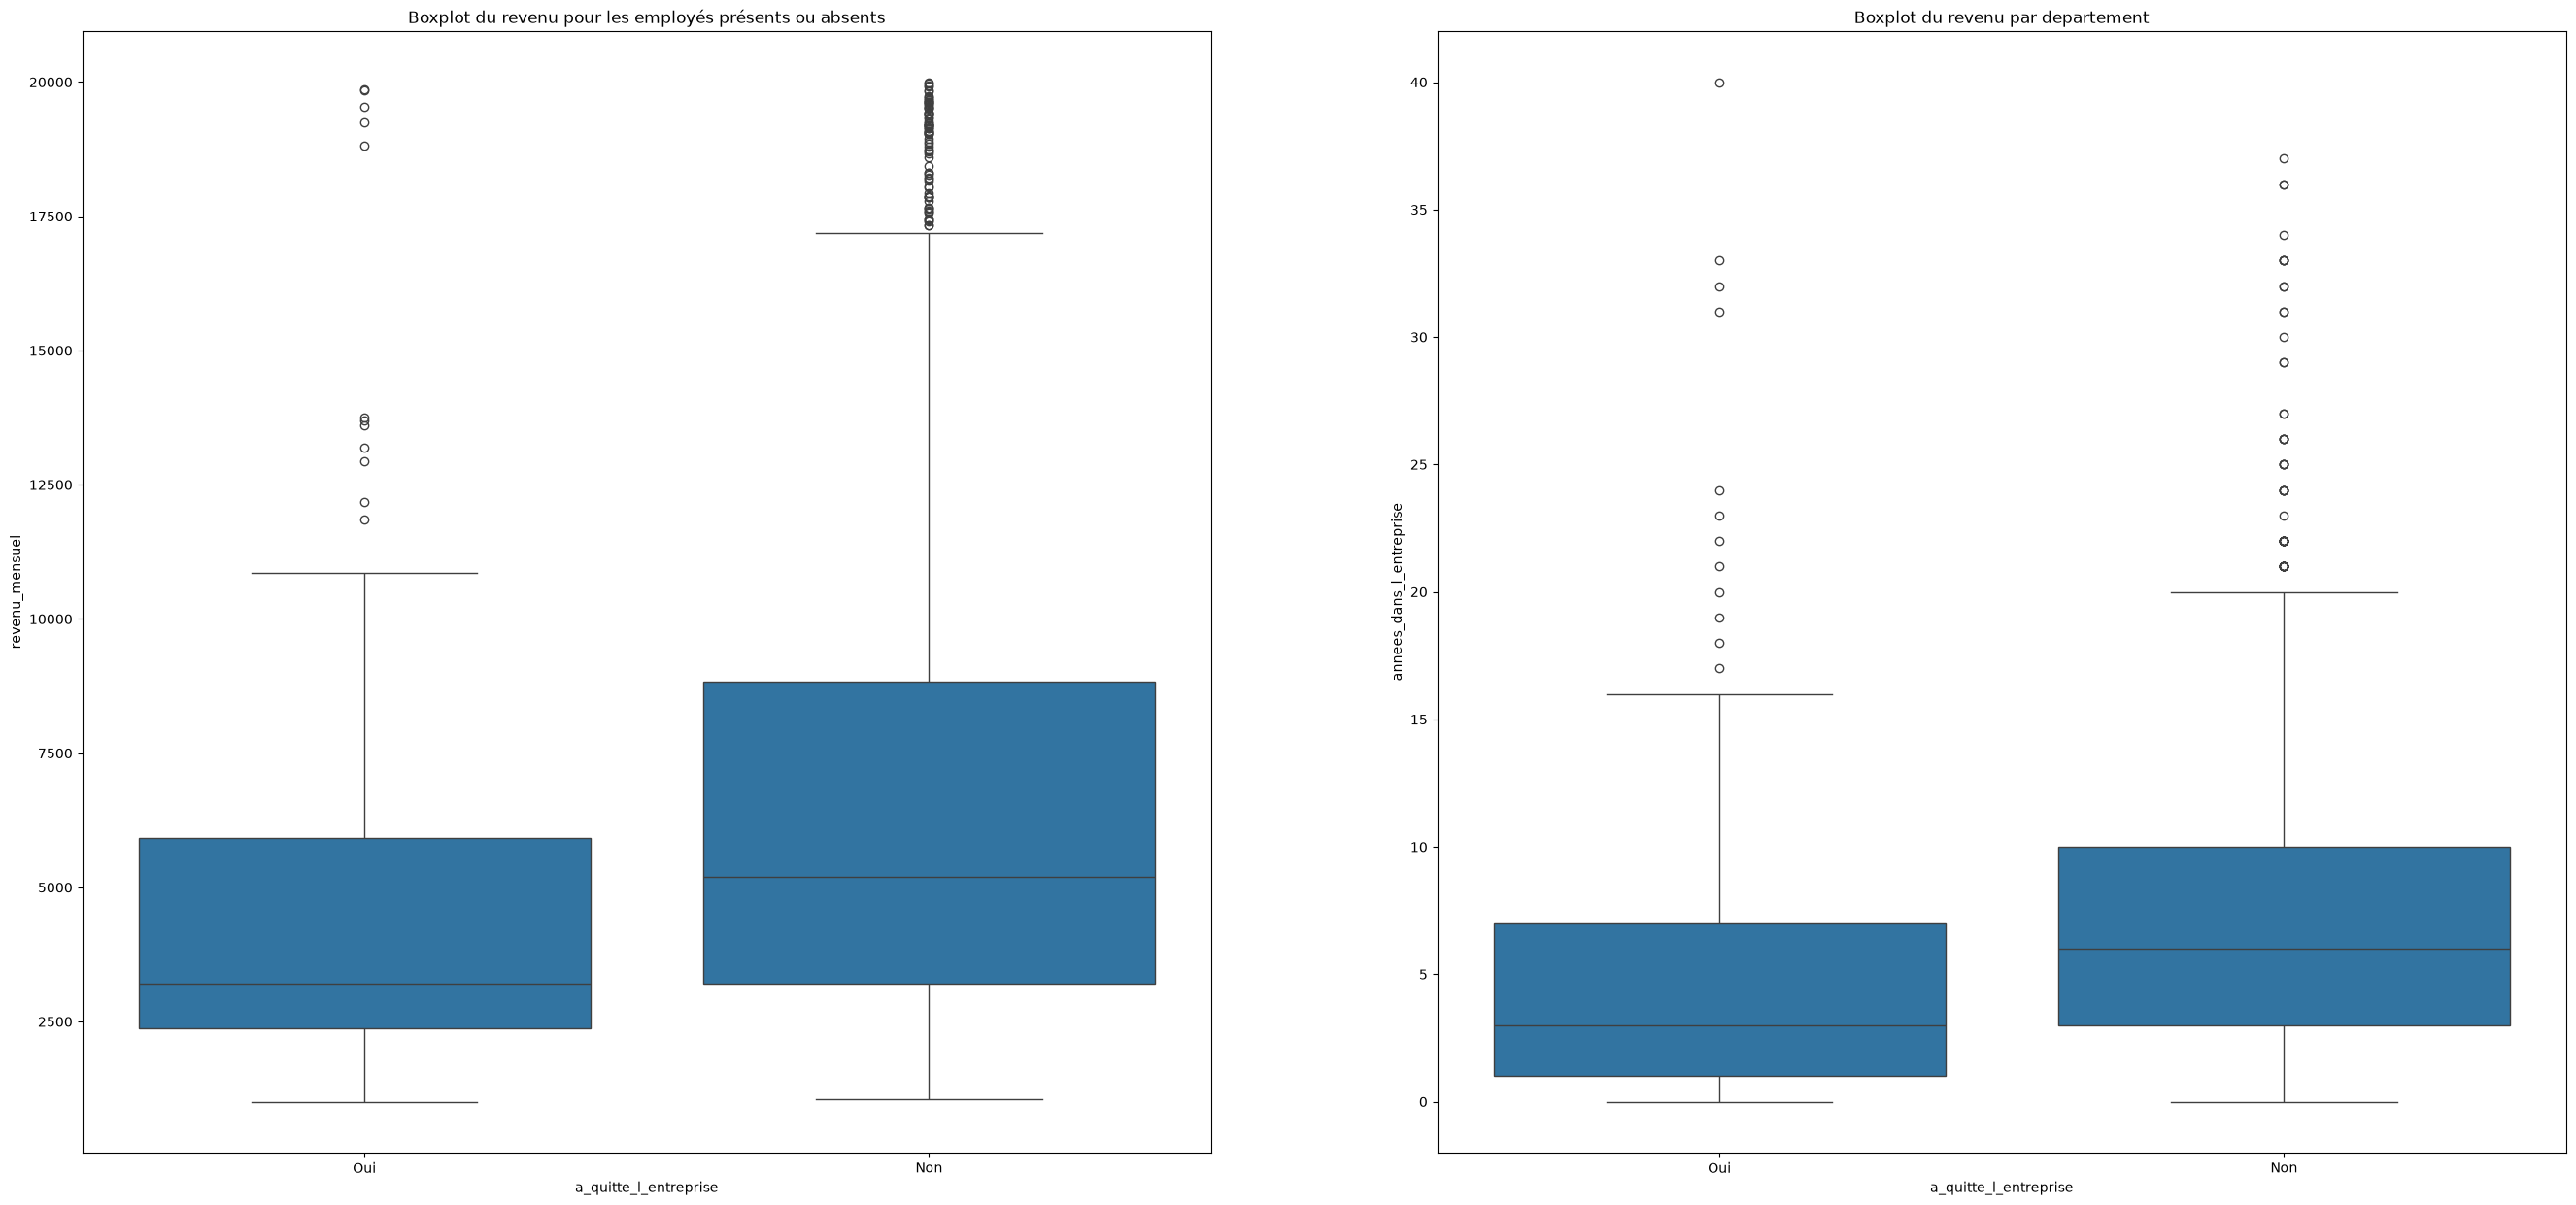

In [477]:
fig, axes = plt.subplots(1, 2, figsize=(33,15))
sns.boxplot(data=df, y="revenu_mensuel", x="a_quitte_l_entreprise", ax=axes[0]).set_title("Boxplot du revenu pour les employés présents ou absents")
sns.boxplot(data=df, y="annees_dans_l_entreprise", x="a_quitte_l_entreprise", ax=axes[1]).set_title("Boxplot du revenu par departement")

## 4. Analyse Bivarié

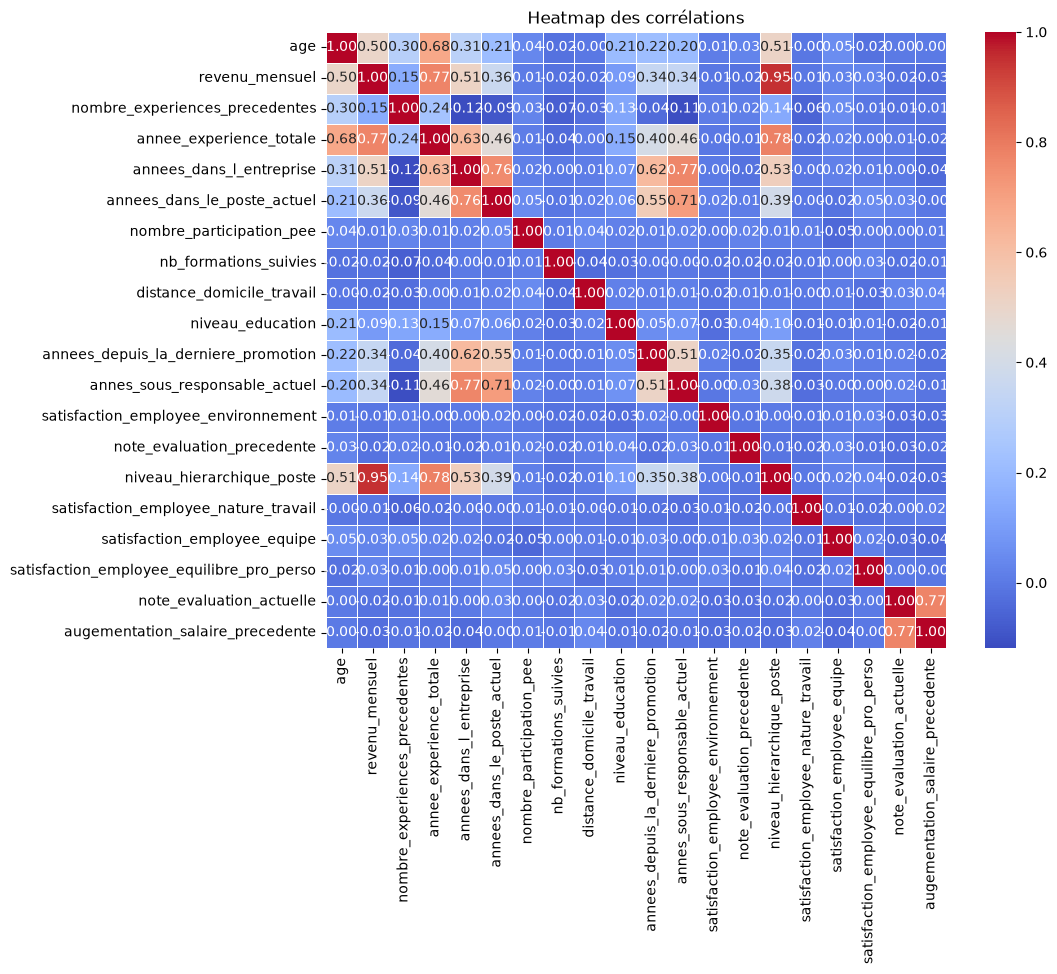

In [ ]:
corr_matrix = df.corr(effectifs_tries = df['Profession'].value_counts()

# 3. Tracé du diagramme en barres horizontales avec Pandas
plt.figure(figsize=(8, 5))
effectifs_tries.plot(kind='barh', color='cornflowerblue', edgecolor='black')

# 4. Mise en forme du graphique
plt.title("Distribution des professions (triée par fréquence)")
plt.xlabel("Effectif (nombre d'individus)")
plt.ylabel("Modalités")

# Inverser l'axe Y pour afficher la modalité la plus fréquente tout en haut
plt.gca().invert_yaxis()

# Affichage
plt.tight_layout()
plt.show())
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5).set_title("Heatmap des corrélations")
plt.show()

In [491]:
ct_heures_supplémentaires = pd.crosstab(df["heure_supplementaires"], df["a_quitte_l_entreprise"])
display(ct_heures_supplémentaires)

ct_genre = pd.crosstab(df["genre"], df["a_quitte_l_entreprise"])
display(ct_genre)

a_quitte_l_entreprise,Non,Oui
heure_supplementaires,,
Non,944,110
Oui,289,127


a_quitte_l_entreprise,Non,Oui
genre,,
F,501,87
M,732,150


## 5. Feature Engineering

## 6. Préparation des données à la modélisation

In [ ]:
display(df)

,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel,a_quitte_l_entreprise,nombre_participation_pee,nb_formations_suivies,distance_domicile_travail,niveau_education,domaine_etude,frequence_deplacement,annees_depuis_la_derniere_promotion,annes_sous_responsable_actuel,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,note_evaluation_actuelle,heure_supplementaires,augementation_salaire_precedente
0,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,8,6,4,Oui,0,0,1,2,Infra & Cloud,Occasionnel,0,5,2,3,2,4,1,1,3,Oui,11
1,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,10,10,7,Non,1,3,8,1,Infra & Cloud,Frequent,1,7,3,2,2,2,4,3,4,Non,23
2,37,M,2090,Célibataire,Consulting,Consultant,6,7,0,0,Oui,0,3,2,2,Autre,Occasionnel,0,0,4,2,1,3,2,3,3,Oui,15
3,33,F,2909,Marié(e),Consulting,Assistant de Direction,1,8,8,7,Non,0,3,3,4,Infra & Cloud,Frequent,3,0,4,3,1,3,3,3,3,Oui,11
4,27,M,3468,Marié(e),Consulting,Consultant,9,6,2,2,Non,1,3,2,1,Transformation Digitale,Occasionnel,2,2,1,3,1,2,4,3,3,Non,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,36,M,2571,Marié(e),Consulting,Consultant,4,17,5,2,Non,1,3,23,2,Transformation Digitale,Frequent,0,3,3,4,2,4,3,3,3,Non,17
1466,39,M,9991,Marié(e),Consulting,Manager,4,9,7,7,Non,1,5,6,1,Transformation Digitale,Occasionnel,1,7,4,2,3,1,1,3,3,Non,15
1467,27,M,6142,Marié(e),Consulting,Tech Lead,1,6,6,2,Non,1,0,4,3,Infra & Cloud,Occasionnel,0,3,2,4,2,2,2,3,4,Oui,20
1468,49,M,5390,Marié(e),Commercial,Cadre Commercial,2,17,9,6,Non,0,3,2,3,Transformation Digitale,Frequent,0,8,4,2,2,2,4,2,3,Non,14


In [ ]:
# Avec les précédents filtre de lignes, l'index du dataframe n'est plus continue
# Pour éviter que cela pose problème, on recréé un index de 0
df = df.reset_index(drop=True).copy()

# sparse_output permet de retourner directement un array
encoder = preprocessing.OneHotEncoder(sparse_output=False, drop="first")

# One hot Encoding statut_marital
label_statut_marital = (encoder.fit_transform(df[["statut_marital"]]))
statut_marital_onehot = pd.DataFrame(
    data=label_statut_marital,
    columns=encoder.get_feature_names_out()
)
df = pd.concat([df, statut_marital_onehot], axis=1)

# One hot Encoding genre
label_genre = (encoder.fit_transform(df[["genre"]]))
genre_onehot = pd.DataFrame(
    data=label_genre,
    columns=encoder.get_feature_names_out()
)
df = pd.concat([df, genre_onehot], axis=1)

# One hot Encoding departement
label_departement = (encoder.fit_transform(df[["departement"]]))
departement_onehot = pd.DataFrame(
    data=label_departement,
    columns=encoder.get_feature_names_out()
)
df = pd.concat([df, departement_onehot], axis=1)

# One hot Encoding  a_quitte_l_entreprise
label_a_quitte_l_entreprise = (encoder.fit_transform(df[["a_quitte_l_entreprise"]]))
a_quitte_l_entreprise_onehot = pd.DataFrame(
    data=label_a_quitte_l_entreprise,
    columns=encoder.get_feature_names_out()
)
df = pd.concat([df, a_quitte_l_entreprise_onehot], axis=1)

# One hot Encoding poste
label_poste = (encoder.fit_transform(df[["poste"]]))
poste_onehot = pd.DataFrame(
    data=label_poste,
    columns=encoder.get_feature_names_out()
)
df = pd.concat([df, poste_onehot], axis=1)

# One hot Encoding domaine_etude
label_domaine_etude = (encoder.fit_transform(df[["domaine_etude"]]))
domaine_etude_onehot = pd.DataFrame(
    data=label_domaine_etude,
    columns=encoder.get_feature_names_out()
)
df = pd.concat([df, domaine_etude_onehot], axis=1)

# One hot Encoding frequence_deplacement
label_heure_supplementaires = (encoder.fit_transform(df[["heure_supplementaires"]]))
heure_supplementaires_onehot = pd.DataFrame(
    data=label_heure_supplementaires,
    columns=encoder.get_feature_names_out()
)
df = pd.concat([df, heure_supplementaires_onehot], axis=1)


# On supprime ensuite les colonnes qui viennent d'être encodées
df = df.drop(["statut_marital", "genre", "departement", "a_quitte_l_entreprise", "poste", "domaine_etude", "frequence_deplacement", "heure_supplementaires"], axis=1)
display(df)

,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel,a_quitte_l_entreprise,nombre_participation_pee,nb_formations_suivies,distance_domicile_travail,niveau_education,domaine_etude,frequence_deplacement,annees_depuis_la_derniere_promotion,annes_sous_responsable_actuel,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,note_evaluation_actuelle,heure_supplementaires,augementation_salaire_precedente,statut_marital_Divorcé(e),statut_marital_Marié(e),genre_M,departement_Consulting,departement_Ressources Humaines,a_quitte_l_entreprise_Oui,poste_Cadre Commercial,poste_Consultant,poste_Directeur Technique,poste_Manager,poste_Représentant Commercial,poste_Ressources Humaines,poste_Senior Manager,poste_Tech Lead,domaine_etude_Entrepreunariat,domaine_etude_Infra & Cloud,domaine_etude_Marketing,domaine_etude_Ressources Humaines,domaine_etude_Transformation Digitale,heure_supplementaires_Oui
0,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,8,6,4,Oui,0,0,1,2,Infra & Cloud,Occasionnel,0,5,2,3,2,4,1,1,3,Oui,11,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,10,10,7,Non,1,3,8,1,Infra & Cloud,Frequent,1,7,3,2,2,2,4,3,4,Non,23,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,37,M,2090,Célibataire,Consulting,Consultant,6,7,0,0,Oui,0,3,2,2,Autre,Occasionnel,0,0,4,2,1,3,2,3,3,Oui,15,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,33,F,2909,Marié(e),Consulting,Assistant de Direction,1,8,8,7,Non,0,3,3,4,Infra & Cloud,Frequent,3,0,4,3,1,3,3,3,3,Oui,11,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4,27,M,3468,Marié(e),Consulting,Consultant,9,6,2,2,Non,1,3,2,1,Transformation Digitale,Occasionnel,2,2,1,3,1,2,4,3,3,Non,12,0.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,36,M,2571,Marié(e),Consulting,Consultant,4,17,5,2,Non,1,3,23,2,Transformation Digitale,Frequent,0,3,3,4,2,4,3,3,3,Non,17,0.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1466,39,M,9991,Marié(e),Consulting,Manager,4,9,7,7,Non,1,5,6,1,Transformation Digitale,Occasionnel,1,7,4,2,3,1,1,3,3,Non,15,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1467,27,M,6142,Marié(e),Consulting,Tech Lead,1,6,6,2,Non,1,0,4,3,Infra & Cloud,Occasionnel,0,3,2,4,2,2,2,3,4,Oui,20,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
1468,49,M,5390,Marié(e),Commercial,Cadre Commercial,2,17,9,6,Non,0,3,2,3,Transformation Digitale,Frequent,0,8,4,2,2,2,4,2,3,Non,14,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
